# Dr.Copper v2 - Phase 3: GARCH Volatility modelling

In [1]:
import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import HTML, display

import dr_copper_v2 as dc
from dr_copper_v2.data_loader import ROOT

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 2

warnings.filterwarnings("ignore")

## 1 - Load Phase 1 development outputs

| Period | Role in Phase 3 |
|---|---|
| 2012 | Initial GARCH parameter estimation; no historical GARCH forecast features |
| 2013-2016 | Generate historical GARCH forecasts with expanding monthly refits and daily state updates |
| 2017-2022 | Continue forecasting across the 72 shared Data2 development folds |

XGBoost training rows with GARCH features will begin in 2013, subject to feature availability and label maturity.

In [2]:
data_dir = ROOT / "data" / "processed"
features = pd.read_parquet(data_dir / "features_development.parquet")
splits = pd.read_parquet(data_dir / "pca" / "n_components_12" / "splits.parquet")

log_returns = features["copper_ret1d"].loc["2012-01-01":"2022-12-31"]
initial_garch_returns = log_returns.loc["2012-01-01":"2012-12-31"]
data1_feature_returns = log_returns.loc["2013-01-01":"2016-12-31"]
data2_returns = log_returns.loc["2017-01-01":"2022-12-31"]

## 2 - GARCH(1,1): Data1 fits

Compare Gaussian and standardized Student-t innovations on the same 2012-2016 returns.

Parameters are estimated by maximum likelihood; lower BIC favors fit after penalizing parameter count. Returns are multiplied by 100 for numerical stability.

In [3]:
data1_returns = log_returns.loc["2012-01-01":"2016-12-31"]
garch_comparison, garch_fits = dc.compare_garch_models(data1_returns)
garch_comparison

,nobs,converged,BIC,omega,alpha,beta,persistence,nu,delta_BIC
Student-t,1256,True,4048.604358,0.029544,0.045869,0.954131,1.0,2.684328,0.0
Gaussian,1256,True,4345.13565,0.046454,0.039715,0.936647,0.976362,NaN,296.531292


### Standardized residual checks

With zero mean, standardized residuals are `return / conditional_volatility`, in matching units. Ljung-Box on these residuals assesses remaining signed-return dependence; on their squares it assesses remaining variance dependence.

Q-Q plots compare each model's residuals with its own innovation distribution; Student-t quantiles are standardized to unit variance. Dashed ACF limits are approximate IID references.

In [4]:
residual_checks = dc.garch_residual_summary(garch_fits, lags=[5, 10, 20])
display(HTML(residual_checks.to_html(float_format=lambda value: f"{value:.3g}")))

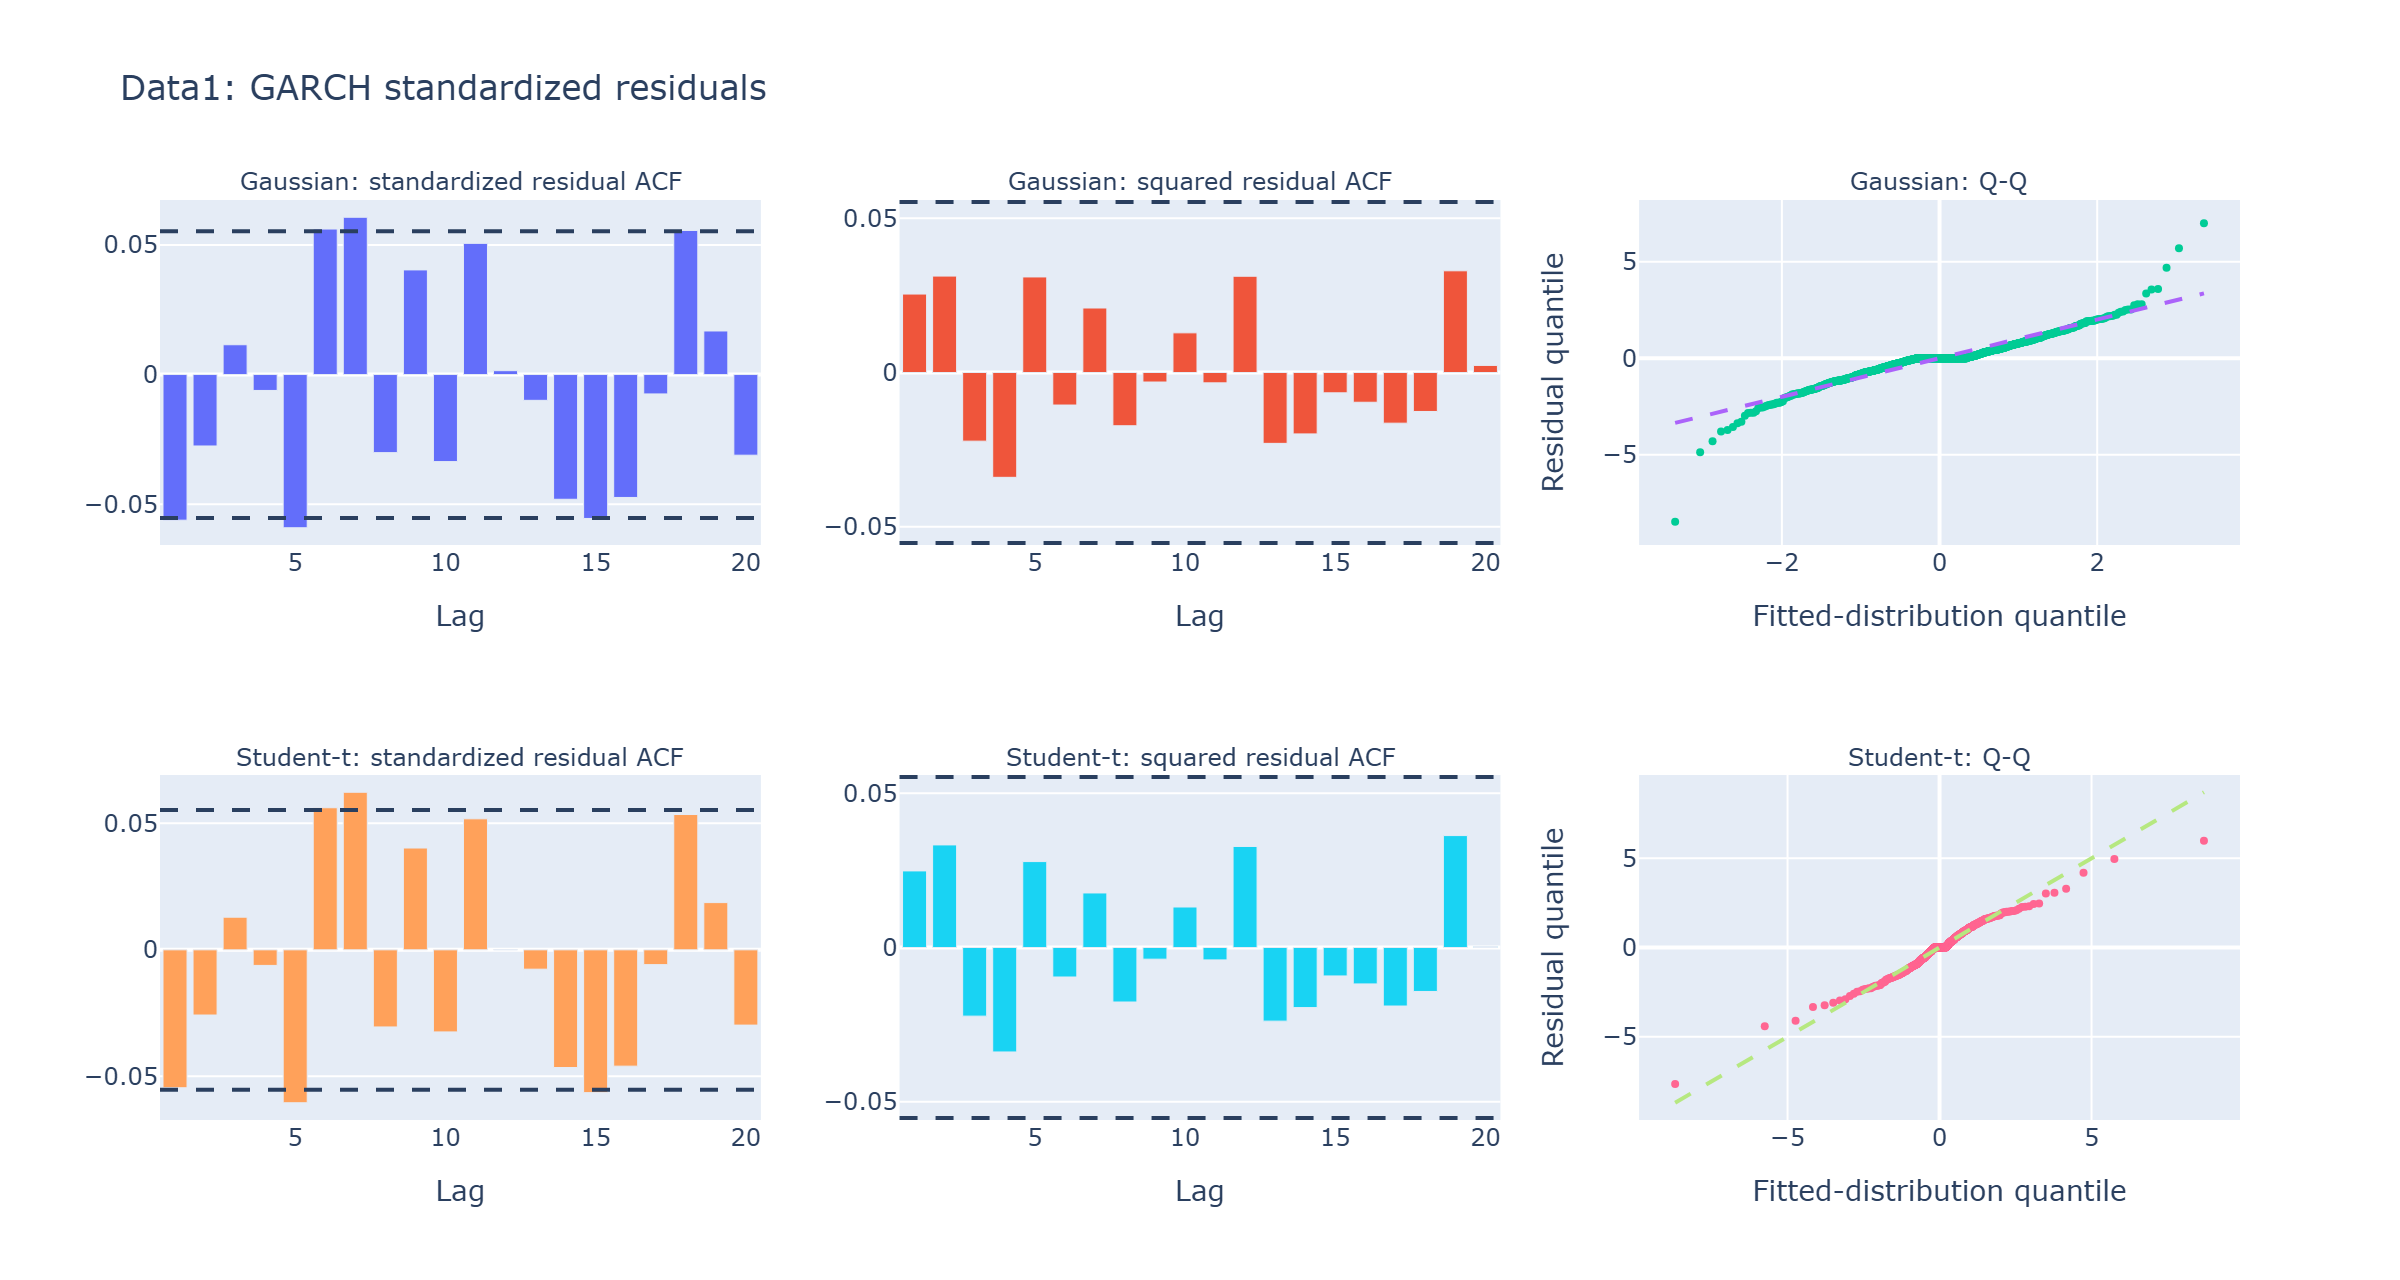

In [5]:
fig = dc.plot_garch_residuals(garch_fits, nlags=20)
fig.show()

### Data1 interpretation

Both fits converge. Student-t lowers BIC by about **296.5**, but its persistence is at the **1.0 boundary**, compared with approximately **0.976** for Gaussian GARCH. We therefore cannot interpret the Student-t fit as having a finite mean-reverting unconditional variance.

Neither model rejects zero squared-residual autocorrelation at the displayed lags, while signed-residual dependence remains through lags 10 and 20 (p < 0.02). The Q-Q plots show substantial Gaussian tail departures; Student-t is closer overall but still imperfect in the extremes.

## 3 - Monthly walk-forward GARCH forecasts

Fit first on 2012, then refit both specifications monthly on expanding history. Extend the same monthly split rule across 2013-2016 and reuse the saved 72 Data2 folds. A failed fit stops the calculation rather than silently substituting another model.

At each session t, consume the completed return and update the variance state before forecasting t+1. Parameters remain fixed within the month. Five-session variance is the **sum of forecasts for t+1 through t+5**, not the forecast for session t+5 alone; volatility is its square root. With our zero-mean model this sum is the model-implied variance of the cumulative log return.

In [6]:
early_split_rows = []
for train, block in dc.walk_forward_split(
    log_returns.to_frame(), test_start="2013-01-01", test_end="2017-01-01"
):
    early_split_rows.append(
        {
            "train_start": train.index.min(),
            "train_end": train.index.max(),
            "test_start": block.index.min(),
            "test_end": block.index.max(),
        }
    )
garch_splits = pd.concat(
    [pd.DataFrame(early_split_rows), splits[early_split_rows[0].keys()]],
    ignore_index=True,
)

garch_forecasts, garch_refits = dc.forecast_garch_models(log_returns, garch_splits)

In [7]:
garch_forecasts.head()

,date,model,fold,fit_end,variance_1d,variance_5d,volatility_1d,volatility_5d
0,2013-01-02,Gaussian,2013-01,2012-12-31,0.000074,0.000365,0.008574,0.019094
1,2013-01-03,Gaussian,2013-01,2012-12-31,0.000073,0.000363,0.008556,0.019056
2,2013-01-04,Gaussian,2013-01,2012-12-31,0.000073,0.000362,0.008539,0.019017
3,2013-01-07,Gaussian,2013-01,2012-12-31,0.000073,0.000360,0.008522,0.018979
4,2013-01-08,Gaussian,2013-01,2012-12-31,0.000072,0.000359,0.008505,0.018942


In [8]:
garch_refits.groupby("model")["persistence"].agg(["min", "median", "max"])

,min,median,max
model,,,
Gaussian,0.967550,0.97767,0.991158
Student-t,0.992316,1.00000,1.000000


Both models converge in all 120 monthly fits.

## 4 - Data2 variance forecast comparison

The benchmark is Phase 1's annualized 21-session volatility. Square it and divide by 252 to obtain daily variance; use five times that variance for the next five sessions. This assumes the benchmark's daily variance stays constant over the forecast window.

Compare forecasts by MSE against the next squared log return or the sum of the next five squared log returns. Score all three methods on the same Data2 origins within each horizon. Five-session windows overlap, so the MSEs are descriptive.

In [9]:
variance_scores = dc.compare_variance_forecasts(
    garch_forecasts,
    data2_returns,
    features["copper_vol21d"],
)
display(HTML(variance_scores.to_html(formatters={"MSE": "{:.6e}".format})))

Use **zero-mean Gaussian GARCH(1,1)** for Phase 4. It has the lowest Data2 variance MSE at both horizons, with five-session MSE **16.2% below** the 21-session benchmark.

## 5 - Export development GARCH forecasts

Save the Gaussian forecasts indexed by the completed CPER session. `fit_end` is the last return used to estimate parameters. Volatility is in decimal log-return units; five-session values cover the full next five sessions.

In [10]:
gaussian_forecasts = (
    garch_forecasts.loc[garch_forecasts["model"].eq("Gaussian")]
    .set_index("date")
    .sort_index()
)

garch_path = data_dir / "garch" / "gaussian_forecasts_development.parquet"
garch_path.parent.mkdir(parents=True, exist_ok=True)
gaussian_forecasts.to_parquet(garch_path)
print(f"Saved {len(gaussian_forecasts):,} forecasts to {garch_path.relative_to(ROOT)}")

Saved 2,516 forecasts to data\processed\garch\gaussian_forecasts_development.parquet


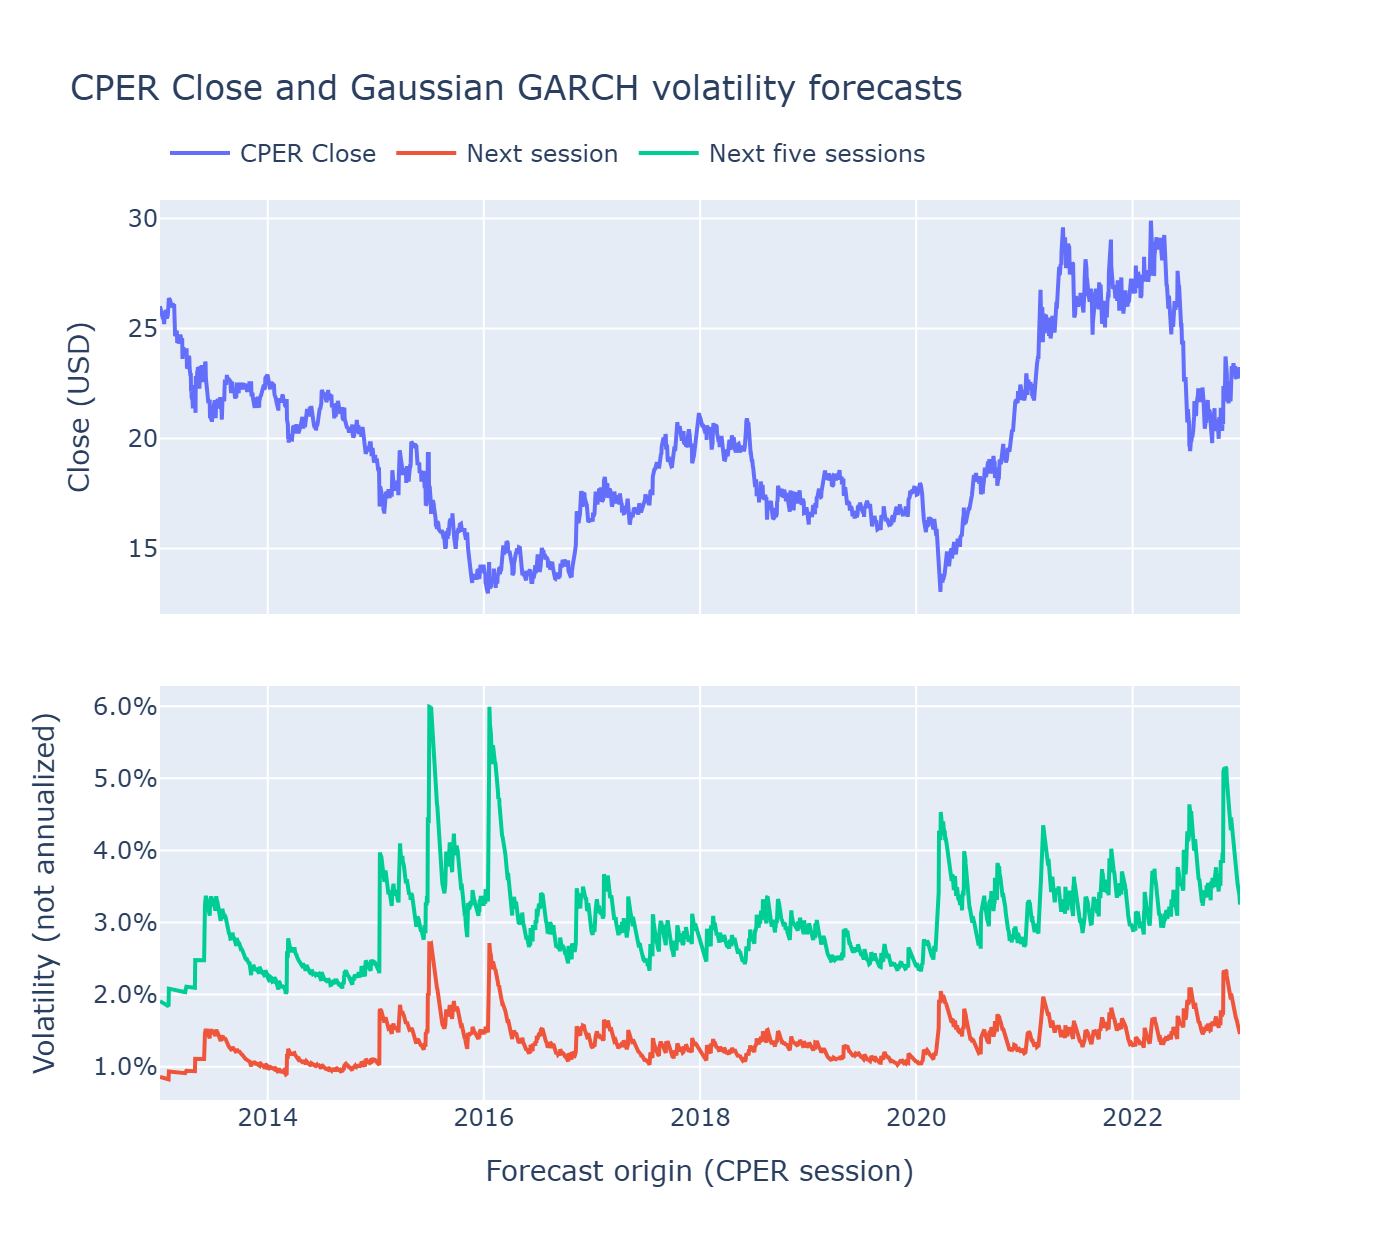

In [11]:
cper_close = pd.read_parquet(data_dir / "raw_development.parquet", columns=["copper"])[
    "copper"
]
forecast_fig = dc.plot_garch_forecasts(gaussian_forecasts, cper_close)
forecast_fig.show()